In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from sklearn.metrics import roc_curve, roc_auc_score

In [2]:
df1=pd.read_csv("train_transaction.csv")
df1.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
df2=pd.read_csv("train_identity.csv");
df2.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [4]:
df1.shape

(590540, 394)

In [5]:
df2.shape

(144233, 41)

In [6]:
df_train = pd.merge(df1, df2, on="TransactionID",how="outer")
df_train.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [7]:
X = df_train.drop(columns=['isFraud'])
y = df_train['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
X_train.shape

(472432, 433)

In [9]:
missing_df = pd.DataFrame({
    'Missing_Count': X_train.isnull().sum(),
    'Missing_Percentage': (X_train.isnull().sum() / len(df_train)) * 100,
    'Dtype': df_train.dtypes
})
missing_df = missing_df[missing_df['Missing_Count'] > 0]
pd.set_option('display.max_rows', None)
print(missing_df.sort_values(
    by='Missing_Percentage',
    ascending=False
))

               Missing_Count  Missing_Percentage    Dtype
id_24               468639.0           79.357707  float64
id_25               468330.0           79.305382  float64
id_07               468318.0           79.303349  float64
id_08               468318.0           79.303349  float64
id_21               468313.0           79.302503  float64
id_26               468310.0           79.301995  float64
id_27               468306.0           79.301317      str
id_22               468306.0           79.301317  float64
id_23               468306.0           79.301317      str
dist2               442276.0           74.893487  float64
D7                  441253.0           74.720256  float64
id_18               436308.0           73.882887  float64
D13                 422692.0           71.577201  float64
D14                 422488.0           71.542656  float64
D12                 420479.0           71.202459  float64
id_03               419240.0           70.992651  float64
id_04         

In [10]:
df_test1=pd.read_csv('test_transaction.csv')
df_test2=pd.read_csv("test_identity.csv");

In [11]:
df_test=pd.merge(df_test1, df_test2, on="TransactionID",how="outer");
df_test.head()

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,id-31,id-32,id-33,id-34,id-35,id-36,id-37,id-38,DeviceType,DeviceInfo
0,3663549,18403224,31.95,W,10409,111.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3663550,18403263,49.00,W,4272,111.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3663551,18403310,171.00,W,4476,574.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3663552,18403310,284.95,W,10989,360.0,150.0,visa,166.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3663553,18403317,67.95,W,18018,452.0,150.0,mastercard,117.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
missing_df_test = pd.DataFrame({
    'Missing_Count': df_test.isnull().sum(),
    'Missing_Percentage': (df_test.isnull().sum() / len(df_test)) * 100,
    'Dtype': df_test.dtypes
})

missing_df_test = missing_df_test[missing_df_test['Missing_Count'] > 0]

pd.set_option('display.max_rows', None)

print(missing_df.sort_values(
    by='Missing_Percentage',
    ascending=False
))

               Missing_Count  Missing_Percentage    Dtype
id_24               468639.0           79.357707  float64
id_25               468330.0           79.305382  float64
id_07               468318.0           79.303349  float64
id_08               468318.0           79.303349  float64
id_21               468313.0           79.302503  float64
id_26               468310.0           79.301995  float64
id_27               468306.0           79.301317      str
id_22               468306.0           79.301317  float64
id_23               468306.0           79.301317      str
dist2               442276.0           74.893487  float64
D7                  441253.0           74.720256  float64
id_18               436308.0           73.882887  float64
D13                 422692.0           71.577201  float64
D14                 422488.0           71.542656  float64
D12                 420479.0           71.202459  float64
id_03               419240.0           70.992651  float64
id_04         

In [13]:
train_cols = set(
    missing_df[
        missing_df['Missing_Percentage'] > 20
    ].index
)
test_cols = set(
    missing_df_test[
        missing_df_test['Missing_Percentage'] > 20
    ].index
)
cols_to_drop = train_cols.union(test_cols)
print("Columns with >20% missing in train OR test:")
print(cols_to_drop)
print("Total columns:", len(cols_to_drop))

Columns with >20% missing in train OR test:
{'id_23', 'id_06', 'V322', 'V52', 'D14', 'V224', 'V327', 'id_27', 'id-01', 'V188', 'V9', 'V141', 'V251', 'V203', 'V337', 'V146', 'M8', 'V277', 'V49', 'dist2', 'id-29', 'V139', 'V268', 'V266', 'V7', 'V8', 'id_33', 'M6', 'id_15', 'V10', 'V278', 'id_17', 'V38', 'V212', 'M7', 'V177', 'M5', 'D13', 'id-09', 'V186', 'V185', 'M4', 'V236', 'D11', 'V244', 'id-06', 'V140', 'V331', 'V216', 'V329', 'V264', 'id_36', 'V274', 'V150', 'id-34', 'V198', 'V230', 'V233', 'id_03', 'V182', 'M9', 'V194', 'id_13', 'V323', 'id-23', 'R_emaildomain', 'V220', 'V154', 'V165', 'V252', 'V158', 'V276', 'id-07', 'id_05', 'V197', 'V326', 'V275', 'id_28', 'V229', 'V214', 'V2', 'V37', 'V51', 'V191', 'id_11', 'V240', 'V172', 'id-26', 'id_37', 'V222', 'id_22', 'V169', 'V181', 'V153', 'V207', 'id-11', 'V195', 'id-05', 'V227', 'id-08', 'V253', 'V259', 'V204', 'id-03', 'V138', 'D3', 'V189', 'V39', 'id_34', 'id_35', 'V248', 'DeviceType', 'id_08', 'id_14', 'id-22', 'id_07', 'V339', 'V1

In [14]:
#remove 
class Dropper(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.cols_to_drop = [
            'V265', 'id_07', 'V159', 'V222', 'V230', 'id-18', 'V160', 'V276', 'V259', 'V337', 'V164', 'D9', 'V151', 'V202', 'V182', 'id-11', 'id-35', 'V37', 'V9', 'V39', 'V141', 'V242', 'V144', 'V176', 'id_34', 'V210', 'V246', 'V193', 'V217', 'id_29', 'V173', 'id_23', 'V209', 'V208', 'M8', 'V140', 'id_15', 'V165', 'V148', 'V158', 'M3', 'id_25', 'V256', 'V195', 'V330', 'V6', 'id-20', 'V224', 'id-38', 'id_30', 'M9', 'V43', 'V172', 'V139', 'V211', 'M5', 'V150', 'V143', 'D3', 'id-07', 'id-30', 'V184', 'id-03', 'DeviceInfo', 'V51', 'V251', 'V333', 'V170', 'V213', 'id-23', 'V2', 'id-21', 'V166', 'V212', 'dist1', 'V168', 'V214', 'id_09', 'D11', 'V5', 'V174', 'V241', 'dist2', 'id_14', 'V146', 'V332', 'V181', 'V218', 'V263', 'id-12', 'V231', 'V194', 'V187', 'id-17', 'V52', 'D13', 'V49', 'V8', 'V44', 'V204', 'V250', 'id-05', 'V42', 'V190', 'id-15', 'V323', 'id_16', 'V334', 'V274', 'id-16', 'V199', 'id_24', 'V191', 'M7', 'V201', 'V145', 'V249', 'V206', 'V235', 'D14', 'V163', 'V258', 'V322', 'V234', 'id-09', 'V267', 'V336', 'id_31', 'V255', 'id_17', 'id_01', 'V142', 'V273', 'V178', 'id_20', 'id-04', 'V277', 'id-28', 'V219', 'V216', 'V253', 'M1', 'V36', 'V3', 'id-01', 'V35', 'V324', 'id_19', 'V161', 'V221', 'R_emaildomain', 'V215', 'V325', 'V327', 'D6', 'V335', 'id_36', 'V147', 'V268', 'id_26', 'id-06', 'id_13', 'V192', 'V205', 'V47', 'V196', 'id_06', 'id_21', 'V338', 'V264', 'id-37', 'D4', 'V239', 'V236', 'V41', 'V229', 'V244', 'V48', 'id-29', 'V1', 'V38', 'id-36', 'V248', 'V149', 'id-13', 'V238', 'V46', 'V179', 'V270', 'id-24', 'id_33', 'V175', 'V261', 'id-02', 'V155', 'id-19', 'V278', 'V153', 'V257', 'V200', 'DeviceType', 'V237', 'id_10', 'V328', 'V228', 'id-27', 'id-08', 'M2', 'V169', 'id_12', 'V40', 'id-31', 'V262', 'V223', 'id_22', 'V269', 'V331', 'id-22', 'id-14', 'V240', 'V138', 'V10', 'id-33', 'V4', 'D8', 'V260', 'V329', 'V225', 'V185', 'id_32', 'D2', 'V189', 'V11', 'M6', 'id_11', 'V220', 'V180', 'id_03', 'id-34', 'id-32', 'V188', 'V156', 'V50', 'id_02', 'V197', 'V227', 'V247', 'V243', 'V183', 'D7', 'V339', 'V162', 'V232', 'V157', 'id_05', 'V326', 'V152', 'V271', 'id_37', 'V233', 'V226', 'V203', 'V275', 'V254', 'id_35', 'D12', 'V171', 'V154', 'V207', 'id_04', 'id-25', 'V186', 'V252', 'V45', 'id_18', 'id-26', 'V245', 'V272', 'V266', 'id_08', 'M4', 'id_27', 'D5', 'V177', 'V7', 'V198', 'id_28', 'V167', 'id_38', 'id-10'
        ]
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X.drop(columns=self.cols_to_drop, errors='ignore')

In [15]:
dropper = Dropper()
X_train = dropper.fit_transform(X_train)
df_test = dropper.transform(df_test)

In [16]:
X_train.head()

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321
40809,3027809,1008491,100.00,R,6177,399.0,150.0,american express,150.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
285886,3272886,7008212,29.99,W,7900,345.0,150.0,mastercard,224.0,debit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
104256,3091256,2071522,107.95,W,11690,111.0,150.0,visa,226.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
507860,3494860,13299752,241.95,W,2616,327.0,150.0,discover,102.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
196382,3183382,4412283,117.00,W,13780,298.0,150.0,visa,226.0,debit,...,117.0,117.0,117.0,117.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
df_test.head()

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321
0,3663549,18403224,31.95,W,10409,111.0,150.0,visa,226.0,debit,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
1,3663550,18403263,49.00,W,4272,111.0,150.0,visa,226.0,debit,...,77.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
2,3663551,18403310,171.00,W,4476,574.0,150.0,visa,226.0,debit,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,263.0,0.0
3,3663552,18403310,284.95,W,10989,360.0,150.0,visa,166.0,debit,...,0.000000,282.540009,282.540009,282.540009,0.0,0.0,0.0,0.0,0.0,0.0
4,3663553,18403317,67.95,W,18018,452.0,150.0,mastercard,117.0,debit,...,67.949997,67.949997,183.850006,67.949997,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
numeric_train = set(X_train.select_dtypes(include='number').columns)
numeric_test = set(df_test.select_dtypes(include='number').columns)
train_cols = set(
    missing_df[
        missing_df['Missing_Percentage'] < 20
    ].index
)
test_cols = set(
    missing_df_test[
        missing_df_test['Missing_Percentage'] < 20
    ].index
)
numeric_cols = numeric_train.union(numeric_test)
cols_to_keep = train_cols.union(test_cols).intersection(numeric_cols)
print("Numeric columns with <20% missing in train OR test:")
print(cols_to_keep)
print("Total columns:", len(cols_to_keep))

Numeric columns with <20% missing in train OR test:
{'V18', 'V56', 'V307', 'V67', 'V116', 'V128', 'C14', 'V24', 'V57', 'V75', 'V282', 'V287', 'V74', 'V96', 'C2', 'V69', 'V112', 'V14', 'card5', 'V320', 'addr1', 'V93', 'V129', 'V102', 'V83', 'V118', 'V34', 'V280', 'V79', 'V133', 'V103', 'V61', 'V32', 'V121', 'V26', 'V90', 'V296', 'V305', 'addr2', 'V23', 'V31', 'V279', 'V63', 'V308', 'V317', 'V313', 'V303', 'V135', 'V283', 'V30', 'V84', 'V29', 'V85', 'V298', 'D1', 'V106', 'V20', 'V122', 'V108', 'V126', 'V65', 'C7', 'V100', 'V286', 'V304', 'V91', 'V291', 'V312', 'V58', 'C1', 'V13', 'V21', 'card2', 'V290', 'V314', 'V82', 'V316', 'C12', 'V297', 'V72', 'C13', 'V77', 'V81', 'V97', 'V130', 'V105', 'D10', 'V16', 'V68', 'V110', 'V124', 'V15', 'D15', 'V19', 'C11', 'V289', 'V89', 'V306', 'V12', 'V104', 'V88', 'C4', 'V54', 'C10', 'V123', 'V71', 'V281', 'V132', 'V107', 'V33', 'V300', 'V288', 'V293', 'V86', 'V294', 'V59', 'V73', 'V292', 'V111', 'V109', 'V295', 'V70', 'C3', 'V99', 'V64', 'V137', 'V22',

In [19]:
#impute
class NumericImputer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.columns = [
            'V286', 'V122', 'V27', 'V33', 'V125', 'V311', 'V105', 'V88', 'V12', 'C11', 'C1', 'V312', 'V94', 'V72', 'V291', 'V317', 'C4', 'V14', 'V106', 'C13', 'V124', 'V61', 'V282', 'V30', 'V68', 'C2', 'V19', 'V298', 'V65', 'V92', 'V22', 'V76', 'V287', 'C5', 'card2', 'V73', 'V17', 'V31', 'V103', 'V34', 'V74', 'V283', 'V321', 'V320', 'V104', 'V314', 'V137', 'V98', 'V306', 'V319', 'V20', 'V87', 'V54', 'V113', 'V318', 'V299', 'V300', 'V285', 'V60', 'V315', 'V26', 'V115', 'C9', 'V28', 'V93', 'V128', 'V91', 'V290', 'V301', 'V307', 'V80', 'V23', 'V116', 'V95', 'card3', 'V25', 'V119', 'C8', 'addr1', 'V288', 'V309', 'V130', 'V75', 'C7', 'card5', 'V295', 'V121', 'V81', 'V280', 'V100', 'V62', 'C14', 'V313', 'V289', 'V86', 'V13', 'V16', 'V133', 'V111', 'V284', 'V305', 'D10', 'C12', 'V79', 'V281', 'V118', 'V279', 'V15', 'V21', 'V90', 'V297', 'V310', 'V66', 'V123', 'V132', 'V59', 'V64', 'V97', 'V77', 'V294', 'addr2', 'V69', 'V58', 'V101', 'V56', 'V53', 'V292', 'V110', 'C6', 'V84', 'V120', 'V134', 'V108', 'V135', 'V102', 'V308', 'V55', 'V302', 'V24', 'V117', 'V316', 'V32', 'V99', 'V126', 'V63', 'V293', 'V78', 'V96', 'V114', 'D1', 'V112', 'V67', 'V29', 'V303', 'V70', 'V296', 'V136', 'V82', 'C3', 'V18', 'V83', 'V127', 'V304', 'V85', 'V107', 'V89', 'V131', 'V57', 'V71', 'V129', 'C10', 'D15', 'V109'
        ]
    def fit(self, X, y=None):
        self.medians_ = X[self.columns].median()
        return self
    def transform(self, X):
        X = X.copy()
        X[self.columns] = X[self.columns].fillna(self.medians_)
        return X

In [20]:
imputer = NumericImputer()
X_train = imputer.fit_transform(X_train)
df_test = imputer.transform(df_test)

In [21]:
X_train.head()

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321
40809,3027809,1008491,100.00,R,6177,399.0,150.0,american express,150.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
285886,3272886,7008212,29.99,W,7900,345.0,150.0,mastercard,224.0,debit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
104256,3091256,2071522,107.95,W,11690,111.0,150.0,visa,226.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
507860,3494860,13299752,241.95,W,2616,327.0,150.0,discover,102.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
196382,3183382,4412283,117.00,W,13780,298.0,150.0,visa,226.0,debit,...,117.0,117.0,117.0,117.0,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
df_test.head()

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321
0,3663549,18403224,31.95,W,10409,111.0,150.0,visa,226.0,debit,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
1,3663550,18403263,49.00,W,4272,111.0,150.0,visa,226.0,debit,...,77.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
2,3663551,18403310,171.00,W,4476,574.0,150.0,visa,226.0,debit,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,263.0,0.0
3,3663552,18403310,284.95,W,10989,360.0,150.0,visa,166.0,debit,...,0.000000,282.540009,282.540009,282.540009,0.0,0.0,0.0,0.0,0.0,0.0
4,3663553,18403317,67.95,W,18018,452.0,150.0,mastercard,117.0,debit,...,67.949997,67.949997,183.850006,67.949997,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
missing_df_test = pd.DataFrame({
    'Missing_Count': df_test.isnull().sum(),
    'Missing_Percentage': (df_test.isnull().sum() / len(df_test)) * 100,
    'Dtype': df_test.dtypes
})

missing_df_test = missing_df_test[missing_df_test['Missing_Count'] > 0]

pd.set_option('display.max_rows', None)

print(missing_df_test.sort_values(
    by='Missing_Percentage',
    ascending=False
))

               Missing_Count  Missing_Percentage Dtype
P_emaildomain          69192           13.655660   str
card4                   3086            0.609050   str
card6                   3007            0.593458   str


In [24]:
missing_df = pd.DataFrame({
    'Missing_Count': X_train.isnull().sum(),
    'Missing_Percentage': (X_train.isnull().sum() / len(X_train)) * 100,
    'Dtype': X_train.dtypes
})
missing_df = missing_df[missing_df['Missing_Count'] > 0]
pd.set_option('display.max_rows', None)
print(missing_df.sort_values(
    by='Missing_Percentage',
    ascending=False
))

               Missing_Count  Missing_Percentage Dtype
P_emaildomain          75591           16.000398   str
card4                   1243            0.263107   str
card6                   1240            0.262472   str


In [25]:
#catimpute
class CategoricalImputer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.columns = [
            'P_emaildomain',
            'card4',
            'card6'
        ]
    def fit(self, X, y=None):
        self.most_frequent_ = {}
        for col in self.columns:
            self.most_frequent_[col] = X[col].mode()[0]
        return self
    def transform(self, X):
        X = X.copy()
        for col in self.columns:
            X[col] = X[col].fillna(self.most_frequent_[col])
        return X

In [26]:
imputer = CategoricalImputer()
X_train = imputer.fit_transform(X_train)
df_test = imputer.transform(df_test)

In [27]:
X_train.head()

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321
40809,3027809,1008491,100.00,R,6177,399.0,150.0,american express,150.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
285886,3272886,7008212,29.99,W,7900,345.0,150.0,mastercard,224.0,debit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
104256,3091256,2071522,107.95,W,11690,111.0,150.0,visa,226.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
507860,3494860,13299752,241.95,W,2616,327.0,150.0,discover,102.0,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
196382,3183382,4412283,117.00,W,13780,298.0,150.0,visa,226.0,debit,...,117.0,117.0,117.0,117.0,0.0,0.0,0.0,0.0,0.0,0.0


In [28]:
df_test.head()

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321
0,3663549,18403224,31.95,W,10409,111.0,150.0,visa,226.0,debit,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
1,3663550,18403263,49.00,W,4272,111.0,150.0,visa,226.0,debit,...,77.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
2,3663551,18403310,171.00,W,4476,574.0,150.0,visa,226.0,debit,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,263.0,0.0
3,3663552,18403310,284.95,W,10989,360.0,150.0,visa,166.0,debit,...,0.000000,282.540009,282.540009,282.540009,0.0,0.0,0.0,0.0,0.0,0.0
4,3663553,18403317,67.95,W,18018,452.0,150.0,mastercard,117.0,debit,...,67.949997,67.949997,183.850006,67.949997,0.0,0.0,0.0,0.0,0.0,0.0


In [29]:
str_cols_train = X_train.select_dtypes(include=['str']).columns.tolist()
print(str_cols_train)

['ProductCD', 'card4', 'card6', 'P_emaildomain']


In [30]:
str_cols_test = df_test.select_dtypes(include=['str']).columns.tolist()
print(str_cols_test)

['ProductCD', 'card4', 'card6', 'P_emaildomain']


In [31]:
str_cols = ['ProductCD', 'card4', 'card6', 'P_emaildomain']
for col in str_cols:
    print(f"\n===== {col} =====")
    print(X_train[col].value_counts(dropna=False))


===== ProductCD =====
ProductCD
W    351450
C     54987
R     30251
H     26425
S      9319
Name: count, dtype: int64

===== card4 =====
card4
visa                308954
mastercard          151547
american express      6658
discover              5273
Name: count, dtype: int64

===== card6 =====
card6
debit              353111
credit             119283
debit or credit        25
charge card            13
Name: count, dtype: int64

===== P_emaildomain =====
P_emaildomain
gmail.com           258203
yahoo.com            80629
hotmail.com          36283
anonymous.com        29774
aol.com              22572
comcast.net           6215
icloud.com            5015
outlook.com           4141
msn.com               3283
att.net               3222
live.com              2418
sbcglobal.net         2342
verizon.net           2159
ymail.com             1919
bellsouth.net         1509
yahoo.com.mx          1235
me.com                1232
cox.net               1135
optonline.net          812
charter.net  

In [32]:
str_cols = ['ProductCD', 'card4', 'card6', 'P_emaildomain']
for col in str_cols:
    print(f"\n===== {col} =====")
    print(df_test[col].value_counts(dropna=False))


===== ProductCD =====
ProductCD
W    360987
C     69266
R     35647
H     29373
S     11418
Name: count, dtype: int64

===== card4 =====
card4
visa                337968
mastercard          158169
american express      7681
discover              2873
Name: count, dtype: int64

===== card6 =====
card6
debit          388028
credit         118662
charge card         1
Name: count, dtype: int64

===== P_emaildomain =====
P_emaildomain
gmail.com           276640
yahoo.com            81850
hotmail.com          40399
anonymous.com        34064
aol.com              24048
comcast.net           6586
icloud.com            6049
outlook.com           4838
att.net               3614
msn.com               3388
sbcglobal.net         2797
live.com              2679
verizon.net           2306
ymail.com             1679
bellsouth.net         1528
yahoo.com.mx          1284
cox.net               1264
me.com                1191
optonline.net          926
live.com.mx            721
charter.net            6

In [33]:
#other
class TopCategoryTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, columns, n_top=10):
        self.columns = columns
        self.n_top = n_top
    def fit(self, X, y=None):
        self.top_categories_ = {}
        for col in self.columns:
            self.top_categories_[col] = (
                X[col]
                .value_counts()
                .head(self.n_top)
                .index
                .tolist()
            )
        return self
    def transform(self, X):
        X = X.copy()
        for col in self.columns:
            X[col] = X[col].where(
                X[col].isin(self.top_categories_[col]),
                'Other'
            )
        return X

In [34]:
transformer = TopCategoryTransformer(
    columns=['P_emaildomain'],
    n_top=10
)
X_train = transformer.fit_transform(X_train)
df_test = transformer.transform(df_test)

In [35]:
str_cols = ['ProductCD', 'card4', 'card6', 'P_emaildomain']
for col in str_cols:
    print(f"\n===== {col} =====")
    print(X_train[col].value_counts(dropna=False))


===== ProductCD =====
ProductCD
W    351450
C     54987
R     30251
H     26425
S      9319
Name: count, dtype: int64

===== card4 =====
card4
visa                308954
mastercard          151547
american express      6658
discover              5273
Name: count, dtype: int64

===== card6 =====
card6
debit              353111
credit             119283
debit or credit        25
charge card            13
Name: count, dtype: int64

===== P_emaildomain =====
P_emaildomain
gmail.com        258203
yahoo.com         80629
hotmail.com       36283
anonymous.com     29774
Other             23095
aol.com           22572
comcast.net        6215
icloud.com         5015
outlook.com        4141
msn.com            3283
att.net            3222
Name: count, dtype: int64


In [36]:
str_cols = ['ProductCD', 'card4', 'card6', 'P_emaildomain']
for col in str_cols:
    print(f"\n===== {col} =====")
    print(df_test[col].value_counts(dropna=False))


===== ProductCD =====
ProductCD
W    360987
C     69266
R     35647
H     29373
S     11418
Name: count, dtype: int64

===== card4 =====
card4
visa                337968
mastercard          158169
american express      7681
discover              2873
Name: count, dtype: int64

===== card6 =====
card6
debit          388028
credit         118662
charge card         1
Name: count, dtype: int64

===== P_emaildomain =====
P_emaildomain
gmail.com        276640
yahoo.com         81850
hotmail.com       40399
anonymous.com     34064
Other             25215
aol.com           24048
comcast.net        6586
icloud.com         6049
outlook.com        4838
att.net            3614
msn.com            3388
Name: count, dtype: int64


In [37]:
#onehotencoding
class CategoricalEncoder(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.columns = ['ProductCD', 'card4', 'card6', 'P_emaildomain']
    def fit(self, X, y=None):
        self.encoder_ = OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        )
        self.encoder_.fit(X[self.columns])
        return self
    def transform(self, X):
        X = X.copy()
        encoded = self.encoder_.transform(X[self.columns])
        encoded_cols = self.encoder_.get_feature_names_out(self.columns)
        encoded_df = pd.DataFrame(
            encoded,
            columns=encoded_cols,
            index=X.index
        )
        X = X.drop(columns=self.columns)
        X = pd.concat([X, encoded_df], axis=1)
        return X

In [38]:
encoder = CategoricalEncoder()
X_train = encoder.fit_transform(X_train)
df_test = encoder.transform(df_test)

In [39]:
X_train.head()

,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,C1,...,P_emaildomain_anonymous.com,P_emaildomain_aol.com,P_emaildomain_att.net,P_emaildomain_comcast.net,P_emaildomain_gmail.com,P_emaildomain_hotmail.com,P_emaildomain_icloud.com,P_emaildomain_msn.com,P_emaildomain_outlook.com,P_emaildomain_yahoo.com
40809,3027809,1008491,100.00,6177,399.0,150.0,150.0,264.0,87.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
285886,3272886,7008212,29.99,7900,345.0,150.0,224.0,143.0,87.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
104256,3091256,2071522,107.95,11690,111.0,150.0,226.0,191.0,87.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
507860,3494860,13299752,241.95,2616,327.0,150.0,102.0,330.0,87.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
196382,3183382,4412283,117.00,13780,298.0,150.0,226.0,441.0,87.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [40]:
df_test.head()

,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,C1,...,P_emaildomain_anonymous.com,P_emaildomain_aol.com,P_emaildomain_att.net,P_emaildomain_comcast.net,P_emaildomain_gmail.com,P_emaildomain_hotmail.com,P_emaildomain_icloud.com,P_emaildomain_msn.com,P_emaildomain_outlook.com,P_emaildomain_yahoo.com
0,3663549,18403224,31.95,10409,111.0,150.0,226.0,170.0,87.0,6.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,3663550,18403263,49.00,4272,111.0,150.0,226.0,299.0,87.0,3.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3663551,18403310,171.00,4476,574.0,150.0,226.0,472.0,87.0,2.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,3663552,18403310,284.95,10989,360.0,150.0,166.0,205.0,87.0,5.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,3663553,18403317,67.95,18018,452.0,150.0,117.0,264.0,87.0,6.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [41]:
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(
    X_train,
    y_train
)

In [42]:
y_train.value_counts()

isFraud
0    455902
1    455902
Name: count, dtype: int64

In [43]:
X_train.shape

(911804, 201)

In [44]:
model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [45]:
X_test = dropper.transform(X_test)
X_test = imputer.transform(X_test)
X_test = imputer.transform(X_test)
X_test = transformer.transform(X_test)
X_test = encoder.transform(X_test)

In [46]:
X_test.head()

,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,C1,...,P_emaildomain_anonymous.com,P_emaildomain_aol.com,P_emaildomain_att.net,P_emaildomain_comcast.net,P_emaildomain_gmail.com,P_emaildomain_hotmail.com,P_emaildomain_icloud.com,P_emaildomain_msn.com,P_emaildomain_outlook.com,P_emaildomain_yahoo.com
316078,3303078,7864752,107.950,7585,553.0,150.0,226.0,264.0,87.0,2.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
116888,3103888,2260318,37.021,3154,408.0,185.0,224.0,NaN,NaN,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
410211,3397211,10361225,59.000,10057,225.0,150.0,224.0,181.0,87.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
251027,3238027,5974846,57.950,6207,355.0,150.0,166.0,143.0,87.0,3.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
191265,3178265,4296816,107.950,11207,361.0,150.0,226.0,325.0,87.0,5.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [47]:
y_pred=model.predict(X_test)

In [48]:
y_prob = model.predict_proba(X_test)[:, 1]

In [49]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.9751667964913469
Precision: 0.8386004514672686
Recall   : 0.35954512460682314
F1 Score : 0.5033022861981372
ROC-AUC  : 0.8990050974010828

Confusion Matrix:
[[113689    286]
 [  2647   1486]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    113975
           1       0.84      0.36      0.50      4133

    accuracy                           0.98    118108
   macro avg       0.91      0.68      0.75    118108
weighted avg       0.97      0.98      0.97    118108



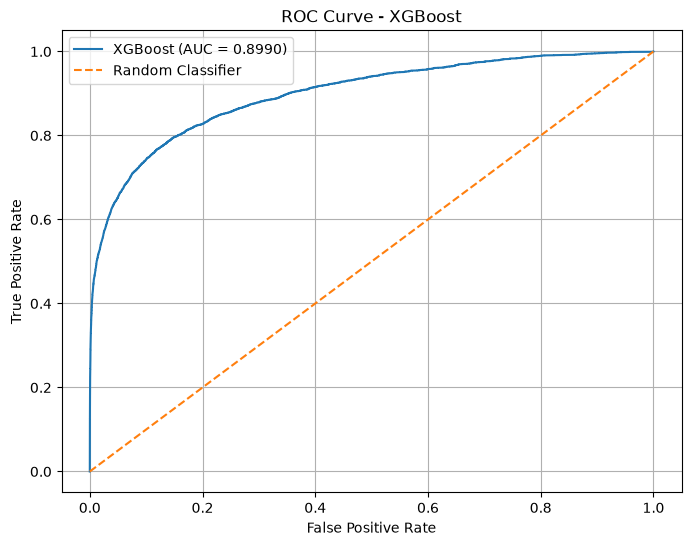

In [50]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'XGBoost (AUC = {auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost')
plt.legend()
plt.grid()
plt.show()

In [51]:
for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_test, y_pred_threshold))
    print("Recall   :", recall_score(y_test, y_pred_threshold))
    print("F1       :", f1_score(y_test, y_pred_threshold))


Threshold: 0.5
Precision: 0.8386004514672686
Recall   : 0.35954512460682314
F1       : 0.5033022861981372

Threshold: 0.4
Precision: 0.7741935483870968
Recall   : 0.4122913138156303
F1       : 0.5380486264603725

Threshold: 0.3
Precision: 0.6754756871035941
Recall   : 0.4638277280425841
F1       : 0.5499928274279157

Threshold: 0.2
Precision: 0.5343719090009891
Recall   : 0.5228647471570288
F1       : 0.5285557050262932

Threshold: 0.1
Precision: 0.3389852116267211
Recall   : 0.6433583353496249
F1       : 0.4440177005928029


In [52]:
import numpy as np

best_threshold = 0
best_f1 = 0

for threshold in np.arange(0.10, 0.51, 0.01):
    pred = (y_prob >= threshold).astype(int)

    f1 = f1_score(y_test, pred)

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Best F1:", best_f1)

Best threshold: 0.3199999999999999
Best F1: 0.5516735173223722


In [53]:
best_threshold = 0.32

y_pred_best = (y_prob >= best_threshold).astype(int)

print("Precision:", precision_score(y_test, y_pred_best))
print("Recall   :", recall_score(y_test, y_pred_best))
print("F1 Score :", f1_score(y_test, y_pred_best))
print(confusion_matrix(y_test, y_pred_best))

Precision: 0.7013811123553565
Recall   : 0.45463343818049845
F1 Score : 0.5516735173223722
[[113175    800]
 [  2254   1879]]


In [54]:
y_prob_test = model.predict_proba(df_test)[:, 1]

In [55]:
best_threshold = 0.32

test_predictions = (y_prob_test >= best_threshold).astype(int)

In [56]:
test_predictions

array([0, 0, 0, ..., 0, 0, 0], shape=(506691,))

In [57]:
df_test.shape

(506691, 201)

In [58]:
X_train.shape

(911804, 201)

In [59]:
submission = pd.DataFrame({
    "TransactionID": df_test["TransactionID"],
    "isFraud": y_prob_test
})

submission.to_csv("fraud_predictions.csv", index=False)

print(submission.head())

   TransactionID   isFraud
0        3663549  0.005067
1        3663550  0.008062
2        3663551  0.012475
3        3663552  0.005280
4        3663553  0.007579


In [65]:
artifacts = {
    "model": model,
    "dropper": dropper,
    "numeric_imputer": NumericImputer,
    "categorical_imputer": CategoricalImputer,
    "transformer": transformer,
    "encoder": encoder,
    "feature_columns": X_train.columns.tolist(),
    "threshold": 0.32
}

In [66]:
import joblib

joblib.dump(artifacts, "fraud_model.pkl")

print("Model saved successfully!")

Model saved successfully!
